# Análisis exploratorio de PM2.5 en Pekín

El conjunto de datos Beijing PM2.5 combina mediciones horarias de PM2.5 de la Embajada de EE. UU. en Pekín con observaciones meteorológicas del Aeropuerto Internacional de Pekín-Capital. Mide desde 2010 a 2014. Cada fila representa una hora. La concentración se expresa en microgramos por metro cúbico.

El EDA responde a cuatro preguntas:

- ¿Qué cobertura tiene la serie y dónde se concentran los faltantes?
- ¿Cómo se distribuye el PM2.5 y qué casos conviene revisar?
- ¿Qué patrones aparecen por hora, mes y año? ¿Cuánto se parecen las observaciones cercanas?
- ¿Qué asociaciones se observan con la meteorología y qué decisiones orientan para el preprocesamiento?

## 1. Carga e inspección inicial

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")

ruta = Path("data") / "dataset.csv"
datos = pd.read_csv(ruta, na_values=["NA"])
objetivo = "pm2.5"
meteo_numericas = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

print(f"{len(datos):,} filas · {datos.shape[1]} columnas")
display(datos.head())
display(datos.dtypes.astype(str).rename("Tipo leído por pandas").to_frame())

43,824 filas · 13 columnas


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


,Tipo leído por pandas
No,int64
year,int64
month,int64
day,int64
hour,int64
pm2.5,float64
DEWP,int64
TEMP,float64
PRES,float64
cbwd,str


## 2. Diccionario y rol de las variables

| Columnas | Significado | Uso |
| --- | --- | --- |
| `No` | Número de fila | Identificador para comprobar el archivo |
| `year`, `month`, `day`, `hour` | Componentes de la fecha y hora | Eje temporal y patrones de calendario |
| `pm2.5` | Concentración de PM2.5 (µg/m³) | Variable de interés |
| `DEWP`, `TEMP` | Punto de rocío y temperatura ambiente (°C) | Variables meteorológicas numéricas |
| `PRES` | Presión atmosférica (hPa) | Variable meteorológica numérica |
| `cbwd` | Dirección combinada del viento | Variable categórica |
| `Iws` | Velocidad acumulada del viento, expresada en m/s según UCI | Variable meteorológica acumulada |
| `Is`, `Ir` | Horas acumuladas de nieve y lluvia | Variables meteorológicas acumuladas |


## 3. Análisis del horario

Unimos las variables temporales en una fecha. Después comprobamos si existen fechas inválidas, duplicadas, orden y horas sin fila. Después crea `serie` en una cuadrícula horaria, extrae `pm25` y crea `observadas`, que reúne solo las filas con concentración disponible. Analizar esto es imporante ya que si falta una fila intermedia, dos filas seguidas podrían estar separadas por mas de una hora y dificultar el análisis de los retardos.

In [2]:
componentes = ["year", "month", "day", "hour"]
fecha = pd.to_datetime(datos[componentes], errors="coerce").rename("fecha")
fechas_validas = pd.DatetimeIndex(fecha.dropna())
calendario = pd.date_range(
    fechas_validas.min(), fechas_validas.max(), freq="h", name="fecha"
)
horas_sin_fila = calendario.difference(fechas_validas)

control_temporal = pd.Series({
    "Primera hora": calendario.min(),
    "Última hora": calendario.max(),
    "Horas dentro del intervalo": len(calendario),
    "Fechas inválidas": fecha.isna().sum(),
    "Filas con hora repetida (tras la primera)": fechas_validas.duplicated().sum(),
    "Horas sin fila": len(horas_sin_fila),
    "Filas completas repetidas": datos.duplicated().sum(),
    "Identificadores No repetidos": datos["No"].duplicated().sum(),
    "Fechas ordenadas en el CSV": fecha.is_monotonic_increasing,
})
display(control_temporal.to_frame("Resultado"))

if fecha.isna().any() or fechas_validas.has_duplicates:
    raise ValueError("Revisa las fechas inválidas o repetidas antes de continuar.")

serie = datos.set_index(fecha).sort_index().reindex(calendario)
pm25 = serie[objetivo]
observadas = serie.loc[pm25.notna()]

,Resultado
Primera hora,2010-01-01 00:00:00
Última hora,2014-12-31 23:00:00
Horas dentro del intervalo,43824
Fechas inválidas,0
Filas con hora repetida (tras la primera),0
Horas sin fila,0
Filas completas repetidas,0
Identificadores No repetidos,0
Fechas ordenadas en el CSV,True


El CSV contiene las 43.824 horas del intervalo y cada fecha aparece una vez. Una hora puede estar presente aunque no tenga concentración de PM2.5.

## 4. Valores ausentes y su distribución

Calcula el porcentaje ausente por columna y por periodo. Si cambia la cobertura con el tiempo, también puede cambiar qué horas representan los resúmenes de PM2.5.

,Ausentes,% ausente
pm2.5,2067,4.72
No,0,0.00
year,0,0.00
month,0,0.00
day,0,0.00
hour,0,0.00
DEWP,0,0.00
TEMP,0,0.00
PRES,0,0.00
cbwd,0,0.00


,horas,observadas,ausentes,% ausente
Año,,,,
2010,8760,8091,669,7.64
2011,8760,8032,728,8.31
2012,8784,8295,489,5.57
2013,8760,8678,82,0.94
2014,8760,8661,99,1.13


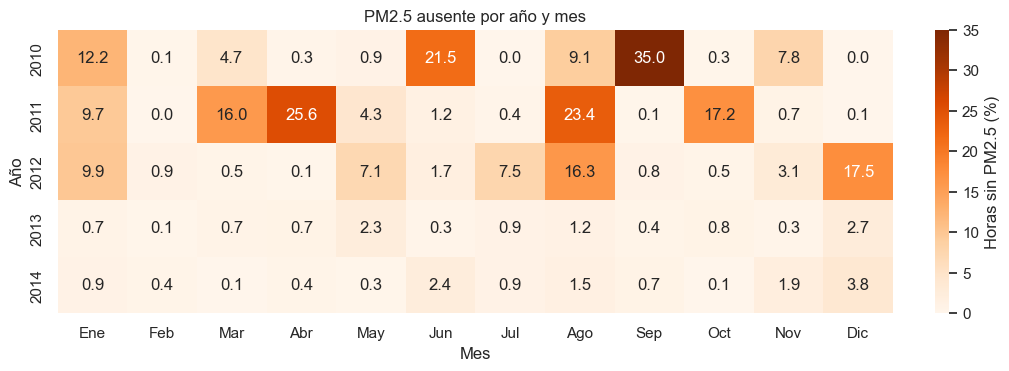

In [18]:
ausencias = datos.isna().sum()
display(pd.DataFrame({
    "Ausentes": ausencias,
    "% ausente": (100 * ausencias / len(datos)).round(2),
}).sort_values("Ausentes", ascending=False))

ausente = pm25.isna()
por_anio = pm25.groupby(pm25.index.year).agg(horas="size", observadas="count")
por_anio.index.name = "Año"
por_anio["ausentes"] = por_anio["horas"] - por_anio["observadas"]
por_anio["% ausente"] = 100 * por_anio["ausentes"] / por_anio["horas"]
display(por_anio.round(2))

ausencia_mensual = 100 * ausente.groupby(
    [ausente.index.year, ausente.index.month]
).mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
sns.heatmap(
    ausencia_mensual, annot=True, fmt=".1f", cmap="Oranges", vmin=0,
    xticklabels=meses, yticklabels=ausencia_mensual.index,
    cbar_kws={"label": "Horas sin PM2.5 (%)"}, ax=ax,
)
ax.set(title="PM2.5 ausente por año y mes", xlabel="Mes", ylabel="Año")
plt.show()

Los valores ausentes de PM2.5 se concentran en unos pocos meses. Septiembre de 2010 es el caso más destacado, con un 35,0 % de las horas sin medición, seguido de abril de 2011 (25,6 %) y agosto de 2011 (23,4 %). En 2013 y 2014, en cambio, el porcentaje anual de horas sin medición ronda el 1 %. Esta diferencia de cobertura conviene tenerla en cuenta al comparar las concentraciones entre meses y años.

Al mirar septiembre de 2010 con más detalle, vimos que casi todas las mediciones que faltan se concentran en dos rachas largas. Como seguimos teniendo datos meteorológicos en esas horas, una posible explicación es que hubiera una interrupción en la medición o en la publicación del PM2.5. Podría deberse a mantenimiento o a un fallo del equipo, aunque con el CSV no podemos saber qué ocurrió.

## 5. Rachas sin PM2.5

Encuentra bloques consecutivos de horas ausentes. Se mide su duración sobre la cuadrícula completa para distinguir faltantes aislados de interrupciones largas.

214 rachas de PM2.5 ausente


,inicio,fin,horas
0,2010-09-21 05:00:00,2010-09-27 15:00:00,155
1,2012-12-23 06:00:00,2012-12-28 12:00:00,127
2,2011-10-03 13:00:00,2011-10-07 15:00:00,99
3,2011-03-17 21:00:00,2011-03-21 15:00:00,91
4,2010-09-27 17:00:00,2010-09-30 20:00:00,76
5,2012-08-18 11:00:00,2012-08-21 12:00:00,74
6,2012-01-14 10:00:00,2012-01-17 11:00:00,74
7,2010-06-04 12:00:00,2010-06-07 11:00:00,72
8,2010-08-13 20:00:00,2010-08-16 15:00:00,68
9,2010-01-23 17:00:00,2010-01-26 11:00:00,67


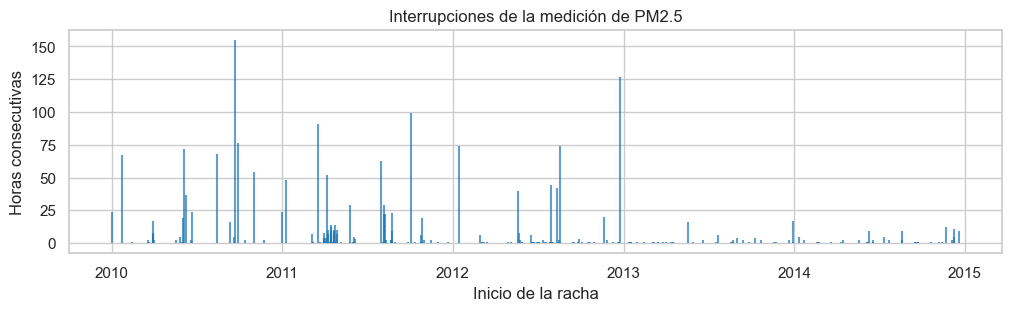

In [4]:
bloques_ausencia = ausente.ne(ausente.shift()).cumsum()
horas_faltantes = ausente.index[ausente]
rachas_ausentes = (
    pd.DataFrame({"fecha": horas_faltantes, "bloque": bloques_ausencia[ausente].to_numpy()})
    .groupby("bloque")["fecha"]
    .agg(inicio="min", fin="max", horas="size")
    .sort_values("horas", ascending=False)
)
print(f"{len(rachas_ausentes)} rachas de PM2.5 ausente")
display(rachas_ausentes.head(10).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 3), layout="constrained")
ax.vlines(rachas_ausentes["inicio"], 0, rachas_ausentes["horas"], color="tab:blue", alpha=0.7)
ax.set(title="Interrupciones de la medición de PM2.5",
       xlabel="Inicio de la racha", ylabel="Horas consecutivas")
plt.show()

Encontramos 214 rachas sin medición de PM2.5. La más larga duró 155 horas en septiembre de 2010 y la segunda, 127 horas en diciembre de 2012. En septiembre de 2010, dos rachas concentran 231 de las 252 horas sin medición. Eso explica por qué ese mes destaca tanto en el mapa de calor.

Durante esas rachas sí hay datos meteorológicos, que vienen de otra estación. Es posible que el equipo de PM2.5 estuviera parado por mantenimiento, que hubiera un fallo del sensor o que las lecturas no se publicaran. Con los datos que tenemos, la causa queda abierta.

De cara al preprocesamiento, probaríamos a estimar los huecos cortos con las mediciones cercanas. Los huecos de varios días los dejaríamos como ausentes, porque interpolarlos podría tapar picos o cambios en la concentración.

## 6. Revisión de valores sospechosos

Cuenta casos que requieren revisión, como concentraciones negativas o un punto de rocío superior a la temperatura. Muestra también los ceros de PM2.5 junto a las dos horas anteriores y posteriores.

In [5]:
controles = pd.Series({
    "PM2.5 negativo": pm25.lt(0).sum(),
    "PM2.5 igual a cero": pm25.eq(0).sum(),
    "Punto de rocío mayor que la temperatura": serie["DEWP"].gt(serie["TEMP"]).sum(),
    "Presión no positiva": serie["PRES"].le(0).sum(),
    "Iws negativo": serie["Iws"].lt(0).sum(),
    "Horas de nieve negativas": serie["Is"].lt(0).sum(),
    "Horas de lluvia negativas": serie["Ir"].lt(0).sum(),
})
display(controles.to_frame("Registros"))
variables_revision = ["No", objetivo, "DEWP", "TEMP", "PRES", "cbwd", "Iws"]
display(serie.loc[serie["DEWP"].gt(serie["TEMP"]), variables_revision])
for hora in pm25.index[pm25.eq(0)]:
    print(f"Entorno de la medición a cero del {hora}")
    margen = pd.Timedelta(hours=2)
    display(serie.loc[hora - margen : hora + margen, variables_revision])

,Registros
PM2.5 negativo,0
PM2.5 igual a cero,2
Punto de rocío mayor que la temperatura,1
Presión no positiva,0
Iws negativo,0
Horas de nieve negativas,0
Horas de lluvia negativas,0


,No,pm2.5,DEWP,TEMP,PRES,cbwd,Iws
fecha,,,,,,,
2010-10-08 07:00:00,6728,349.0,13,12.0,1016.0,NW,0.89


Entorno de la medición a cero del 2012-09-28 10:00:00


,No,pm2.5,DEWP,TEMP,PRES,cbwd,Iws
fecha,,,,,,,
2012-09-28 08:00:00,24033,4.0,-4,18.0,1019.0,NW,118.47
2012-09-28 09:00:00,24034,3.0,-5,19.0,1020.0,NW,129.65
2012-09-28 10:00:00,24035,0.0,-5,20.0,1020.0,NW,139.48
2012-09-28 11:00:00,24036,4.0,-7,22.0,1019.0,NW,149.31
2012-09-28 12:00:00,24037,4.0,-7,22.0,1018.0,NW,160.49


Entorno de la medición a cero del 2012-09-28 15:00:00


,No,pm2.5,DEWP,TEMP,PRES,cbwd,Iws
fecha,,,,,,,
2012-09-28 13:00:00,24038,5.0,-7,23.0,1018.0,NW,170.32
2012-09-28 14:00:00,24039,2.0,-8,24.0,1017.0,NW,181.50
2012-09-28 15:00:00,24040,0.0,-10,24.0,1017.0,NW,192.68
2012-09-28 16:00:00,24041,1.0,-9,23.0,1016.0,NW,204.75
2012-09-28 17:00:00,24042,1.0,-8,23.0,1016.0,NW,213.69


Los dos ceros de PM2.5 aparecen el mismo día y las mediciones cercanas también son bajas, entre 1 y 5. Es posible que en esas horas la concentración estuviera cerca del límite de detección del equipo. Por eso conservaríamos los ceros y los marcaríamos para revisión. Si la fuente confirma que son lecturas inválidas, pasarían a tratarse como ausentes. 

En el caso de DEWP, el punto de rocío estaba muy cerca de la temperatura en las horas de alrededor y solo la supera en un registro. Puede deberse a una pequeña imprecisión de medida o a un error al registrar el dato. Revisaríamos la fuente original y, si no encontramos un valor que podamos verificar, marcaríamos solo DEWP como ausente en esa fila y guardaríamos el valor original para documentar el cambio.

## 7. Distribución de PM2.5 y variables meteorológicas

Compara mediana, media, rango intercuartílico y percentiles altos. Usa dos escalas para apreciar tanto el grueso de PM2.5 como su cola. La transformación log(1 + x) conserva los ceros y se usa aquí para visualizar.

,count,mean,std,min,25%,50%,75%,95%,99%,max
pm2.5,41757.0,98.61,92.05,0.00,29.00,72.00,137.00,284.00,420.00,994.0
DEWP,43824.0,1.82,14.43,-40.00,-10.00,2.00,15.00,22.00,24.00,28.0
TEMP,43824.0,12.45,12.20,-19.00,2.00,14.00,23.00,30.00,34.00,42.0
PRES,43824.0,1016.45,10.27,991.00,1008.00,1016.00,1025.00,1033.00,1038.00,1046.0
Iws,43824.0,23.89,50.01,0.45,1.79,5.37,21.91,113.99,269.12,585.6
Is,43824.0,0.05,0.76,0.00,0.00,0.00,0.00,0.00,0.00,27.0
Ir,43824.0,0.19,1.42,0.00,0.00,0.00,0.00,0.00,6.00,36.0


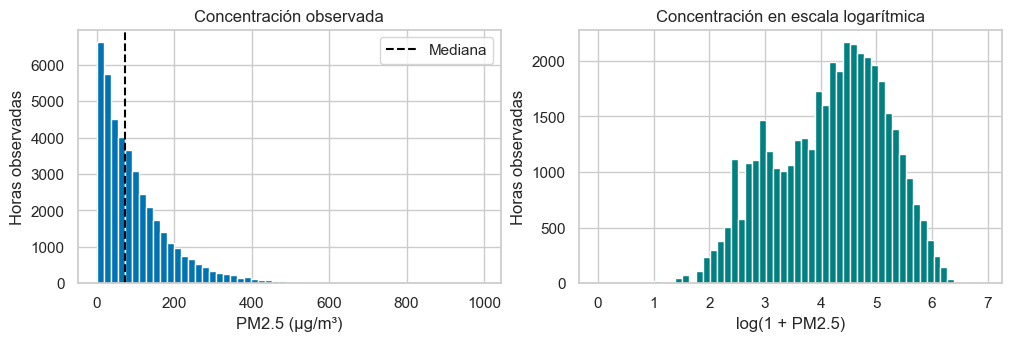

In [6]:
variables_numericas = [objetivo, *meteo_numericas]
display(serie[variables_numericas].describe(percentiles=[.25, .5, .75, .95, .99]).T.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
pm25.hist(bins=55, ax=axes[0])
np.log1p(pm25).hist(bins=55, ax=axes[1], color="teal")
axes[0].axvline(pm25.median(), color="black", linestyle="--", label="Mediana")
axes[0].legend()
axes[0].set(title="Concentración observada", xlabel="PM2.5 (µg/m³)", ylabel="Horas observadas")
axes[1].set(title="Concentración en escala logarítmica",
            xlabel="log(1 + PM2.5)", ylabel="Horas observadas")
plt.show()

La distribución de PM2.5 es asimétrica hacia la derecha. La mitad de las mediciones está en 72 o menos, mientras que el percentil 95 es de 284 y el máximo alcanza los 994. Como las concentraciones más altas pueden elevar la media, usamos la mediana para describir una concentración típica y el percentil 95 para caracterizar los valores altos. La escala logarítmica comprime la cola y deja ver con más claridad dónde se concentra la mayoría de las mediciones.

,Horas con acumulado positivo,% de horas registradas
Is,368,0.84
Ir,1808,4.13


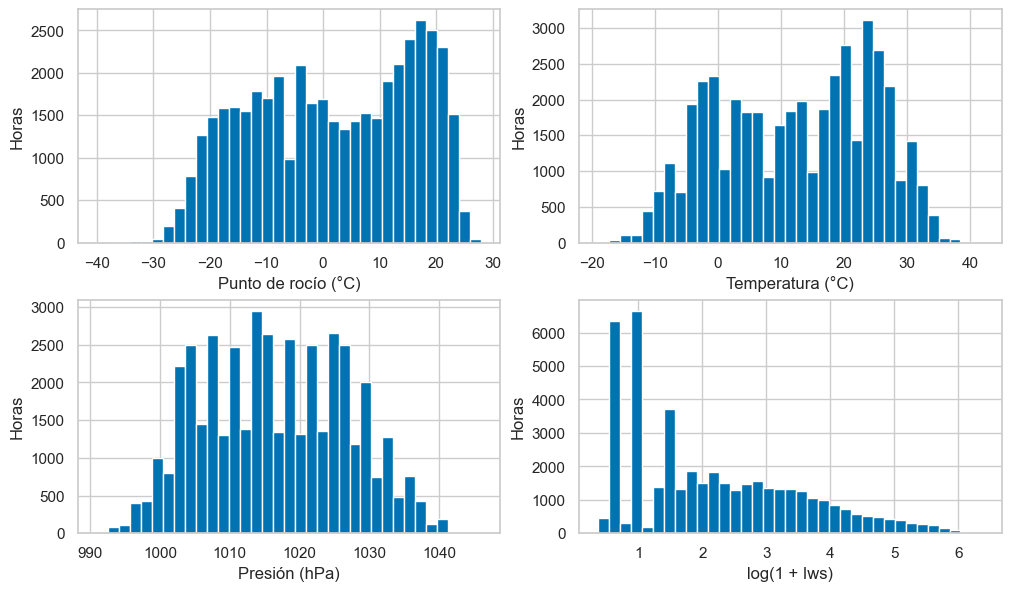

In [7]:
positivos = serie[["Is", "Ir"]].gt(0).sum()
display(pd.DataFrame({
    "Horas con acumulado positivo": positivos,
    "% de horas registradas": (100 * positivos / serie[["Is", "Ir"]].count()).round(2),
}))

fig, axes = plt.subplots(2, 2, figsize=(10, 5.8), layout="constrained")
for ax, variable, etiqueta in zip(
    axes.flat, ["DEWP", "TEMP", "PRES", "Iws"],
    ["Punto de rocío (°C)", "Temperatura (°C)", "Presión (hPa)", "log(1 + Iws)"],
):
    valores = np.log1p(serie[variable]) if variable == "Iws" else serie[variable]
    valores.hist(ax=ax, bins=35)
    ax.set(xlabel=etiqueta, ylabel="Horas")
plt.show()

La velocidad acumulada del viento (`Iws`) se concentra en valores bajos y presenta una cola hacia valores altos. Por eso usamos una escala logarítmica para ver mejor dónde se agrupa la mayoría de las observaciones. Los acumulados de nieve y lluvia son positivos en pocas horas: 0,84 % para la nieve y 4,13 % para la lluvia. Cuando comparemos el PM2.5 entre horas con acumulado cero y positivo, indicaremos el tamaño de cada grupo para interpretar las diferencias.

## 8. Evolución de la serie y cobertura diaria

La serie horaria conserva los huecos. Para comparar días, se dibuja la mediana solo si hay al menos 18 observaciones de las 24 esperadas (75 % de cobertura). Este criterio se aplica únicamente a la visualización diaria.

Días con menos de 18 horas observadas: 104


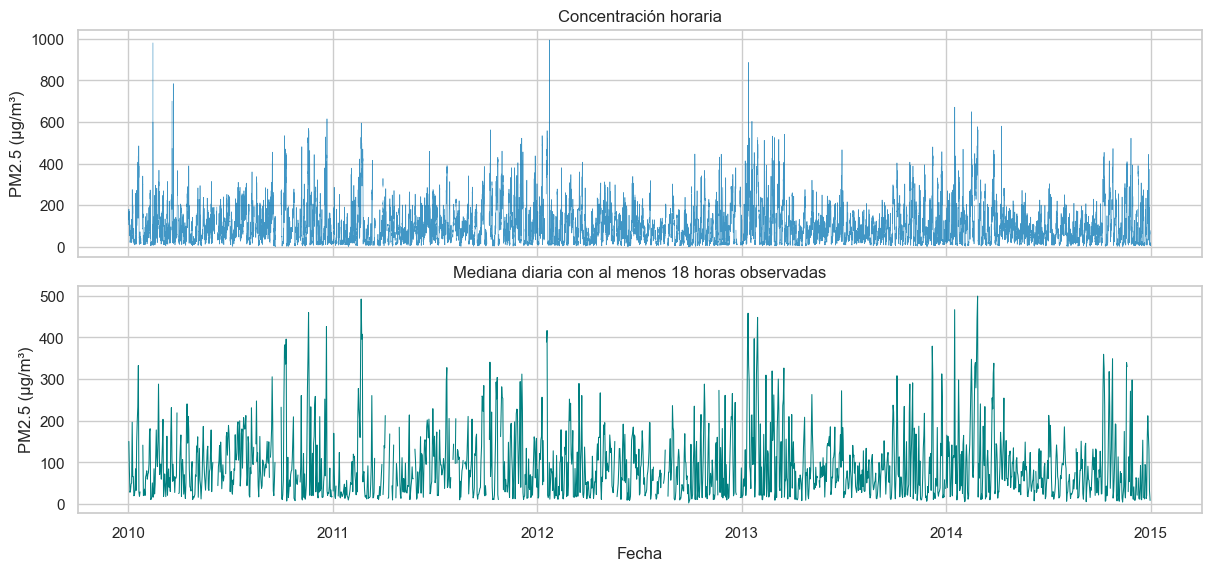

In [8]:
minimo_horas = 18
diario = pm25.resample("D").agg(observadas="count", mediana="median")
mediana_diaria = diario["mediana"].where(diario["observadas"].ge(minimo_horas))
print(f"Días con menos de {minimo_horas} horas observadas: {mediana_diaria.isna().sum()}")

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 5.6), layout="constrained")
axes[0].plot(pm25.index, pm25, linewidth=0.45, alpha=0.75)
axes[0].set(title="Concentración horaria", ylabel="PM2.5 (µg/m³)")
axes[1].plot(mediana_diaria.index, mediana_diaria, linewidth=0.75, color="teal")
axes[1].set(title="Mediana diaria con al menos 18 horas observadas",
            xlabel="Fecha", ylabel="PM2.5 (µg/m³)")
plt.show()

La serie horaria muestra picos que pueden durar pocas horas. La mediana diaria suaviza esas variaciones y permite comparar la concentración típica de un día con la de otros. Para dibujarla exigimos al menos 18 de las 24 horas con medición. Con este criterio, 104 de los 1.826 días quedan sin mediana en el gráfico. Esos huecos indican que faltan mediciones para resumir el día.

## 9. Estacionalidad mensual y diferencias entre años

Recupera el gráfico mensual original y añade dos comprobaciones para interpretarlo: cuántas horas contribuyen a cada grupo y cómo varía la mediana de un mismo mes según el año. Los diagramas muestran los puntos extremos.

,observadas,media,mediana,p95
Ene,3471,115.1,66.0,390.5
Feb,3373,125.7,87.0,387.4
Mar,3556,97.8,70.0,280.0
Abr,3405,83.7,69.0,206.0
May,3609,80.1,69.0,186.0
Jun,3405,96.5,85.0,213.0
Jul,3647,94.3,79.0,226.0
Ago,3337,80.0,70.0,188.4
Sep,3333,85.2,69.0,226.0
Oct,3579,120.4,80.0,350.0


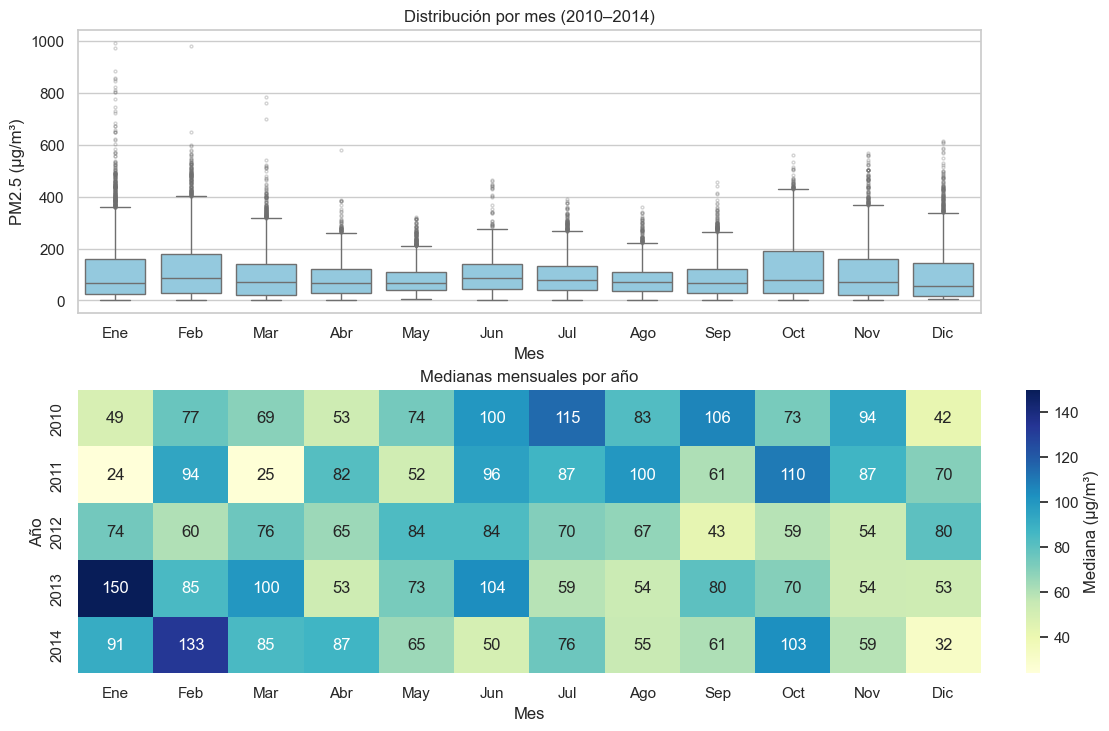

In [9]:
resumen_mensual = observadas.groupby("month")[objetivo].agg(
    observadas="count", media="mean", mediana="median",
    p95=lambda valores: valores.quantile(.95),
)
resumen_mensual.index = meses
display(resumen_mensual.round(1))

mediana_anio_mes = observadas.groupby(["year", "month"])[objetivo].median().unstack()
fig, axes = plt.subplots(2, 1, figsize=(11, 7.2), layout="constrained")
sns.boxplot(data=observadas, x="month", y=objetivo, order=range(1, 13),
            color="skyblue", flierprops={"markersize": 2, "alpha": 0.3}, ax=axes[0])
axes[0].set(xticks=range(12), xticklabels=meses,
            xlabel="Mes", ylabel="PM2.5 (µg/m³)", title="Distribución por mes (2010–2014)")
sns.heatmap(mediana_anio_mes, annot=True, fmt=".0f", cmap="YlGnBu",
            xticklabels=meses, yticklabels=mediana_anio_mes.index,
            cbar_kws={"label": "Mediana (µg/m³)"}, ax=axes[1])
axes[1].set(xlabel="Mes", ylabel="Año", title="Medianas mensuales por año")
plt.show()

Al agrupar los cinco años, la mediana de PM2.5 es de 87 en febrero y de 54 en diciembre. Aun así, el mismo mes puede cambiar mucho de un año a otro. Por ejemplo, en enero la mediana pasó de 24 en 2011 a 150 en 2013.

Para intentar entender esa diferencia, miramos el viento en los dos eneros. En 2011, alrededor del 74 % de las horas tenían viento del noroeste (NW), frente al 38 % en 2013. Esto podría explicar parte de la diferencia, porque en el análisis del viento vemos que con NW suelen darse concentraciones más bajas. Aun así, si miramos solo las horas con NW, la mediana también fue mayor en 2013. Así que el cambio en la dirección del viento parece ser solo una parte de la explicación.

## 10. Ciclo diario

Para cada hora del día, muestra la mediana, el intervalo entre los percentiles 25 y 75 y el porcentaje de horas con medición disponible. El intervalo recoge la dispersión de las observaciones.

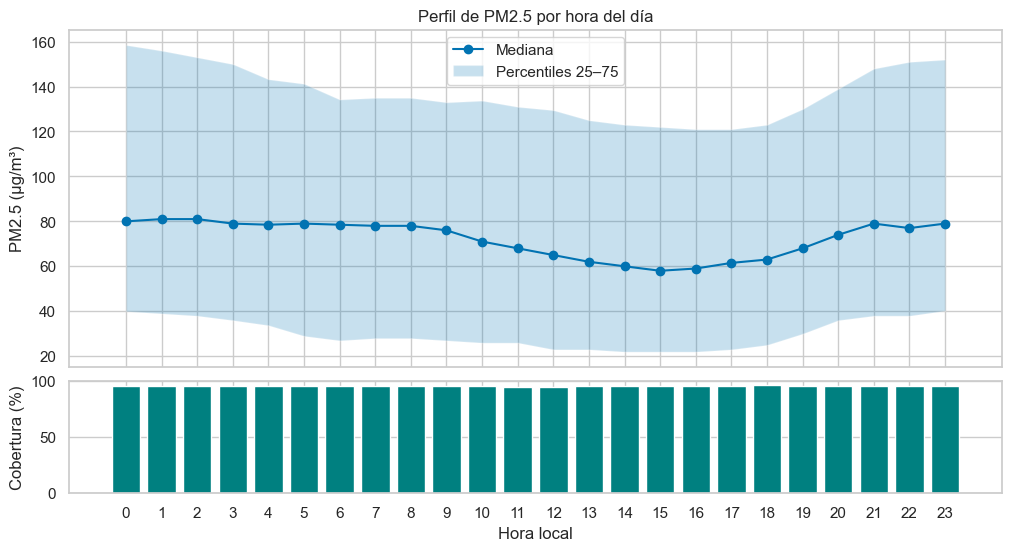

In [10]:
horas_dia = range(24)
perfil_horario = pm25.groupby(pm25.index.hour).agg(
    horas="size", observadas="count", mediana="median",
    p25=lambda valores: valores.quantile(.25),
    p75=lambda valores: valores.quantile(.75),
)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10, 5.4),
                         height_ratios=[3, 1], layout="constrained")
axes[0].plot(horas_dia, perfil_horario["mediana"], marker="o", label="Mediana")
axes[0].fill_between(horas_dia, perfil_horario["p25"], perfil_horario["p75"],
                     alpha=0.22, label="Percentiles 25–75")
axes[0].set(title="Perfil de PM2.5 por hora del día", ylabel="PM2.5 (µg/m³)")
axes[0].legend()
cobertura_horaria = 100 * perfil_horario["observadas"] / perfil_horario["horas"]
axes[1].bar(horas_dia, cobertura_horaria, color="teal")
axes[1].set(xticks=list(horas_dia), xlabel="Hora local", ylabel="Cobertura (%)", ylim=(0, 100))
plt.show()

Al agrupar los cinco años, la mediana de PM2.5 alcanza 81 a la 01:00 y a las 02:00, baja hasta 58 a las 15:00 y vuelve a subir por la tarde. La banda entre los percentiles 25 y 75 es amplia a lo largo del día, lo que indica que las concentraciones pueden variar mucho incluso al comparar mediciones tomadas a la misma hora. El gráfico inferior muestra que la cobertura es similar entre horas.

Para entender por qué vuelve a subir por la tarde, comparamos las 15:00 y las 21:00 dentro del mismo día. La subida mediana fue de 17 entre semana y de 20 los fines de semana. El tráfico de salida del trabajo podría influir, pero la subida también aparece los fines de semana. Otra posibilidad es que al final del día el aire se mezcle menos y las partículas se acumulen cerca del suelo. Con los datos que tenemos podemos ver el patrón, pero para saber qué lo explica necesitaríamos datos de tráfico y de cómo cambia la dispersión a lo largo del día.

## 11. Dependencia entre observaciones cercanas

Calcula la correlación de Pearson entre PM2.5 y la misma serie desplazada de 1 a 168 horas. En cada retardo se usan los pares con ambas mediciones disponibles. Se conserva la cuadrícula horaria aunque haya valores ausentes.

,Correlación,Pares observados
Retardo (h),,
1,0.965,41543
6,0.747,41255
12,0.565,41032
24,0.398,40717
48,0.153,40271
72,0.074,40024
168,0.023,39832


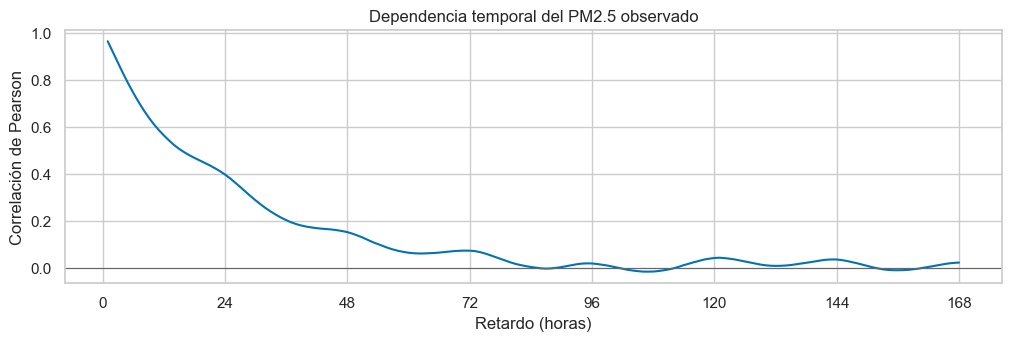

In [11]:
retardos = range(1, 169)
dependencia = pd.DataFrame(
    {
        "Correlación": [pm25.autocorr(lag=h) for h in retardos],
        "Pares observados": [
            (pm25.notna() & pm25.shift(h).notna()).sum() for h in retardos
        ],
    },
    index=pd.Index(retardos, name="Retardo (h)"),
)
display(dependencia.loc[[1, 6, 12, 24, 48, 72, 168]].round(3))

fig, ax = plt.subplots(figsize=(10, 3.3), layout="constrained")
ax.plot(dependencia.index, dependencia["Correlación"], linewidth=1.5)
ax.axhline(0, color="0.4", linewidth=0.8)
ax.set(xticks=range(0, 169, 24), xlabel="Retardo (horas)", ylabel="Correlación de Pearson",
       title="Dependencia temporal del PM2.5 observado")
plt.show()

La correlación es aproximadamente 0,965 a 1 hora y 0,398 a 24 horas. Para una futura predicción, este nivel de persistencia justifica comparar los modelos con una referencia que use la última medición disponible y evaluar en tramos cronológicos.

## 12. Episodios de concentraciones altas

Como criterio exploratorio, agrupa horas consecutivas con PM2.5 igual o superior al percentil 95 del periodo observado. Una hora ausente interrumpe la racha porque se desconoce la concentración en ese momento. El umbral se deriva de la muestra.

Umbral exploratorio: 284 µg/m³ · 288 episodios detectados


,inicio,fin,horas,pico
0,2011-02-20 12:00:00,2011-02-24 05:00:00,90,595.0
1,2014-02-23 15:00:00,2014-02-26 17:00:00,75,577.0
2,2012-01-17 14:00:00,2012-01-20 01:00:00,60,558.0
3,2010-11-17 13:00:00,2010-11-19 13:00:00,49,569.0
4,2014-10-08 15:00:00,2014-10-10 14:00:00,48,454.0
5,2013-01-27 10:00:00,2013-01-29 04:00:00,43,510.0
6,2010-10-09 05:00:00,2010-10-10 22:00:00,42,449.0
7,2014-10-24 14:00:00,2014-10-26 03:00:00,38,472.0
8,2014-11-19 10:00:00,2014-11-20 20:00:00,35,409.0
9,2013-01-22 15:00:00,2013-01-23 16:00:00,26,453.0


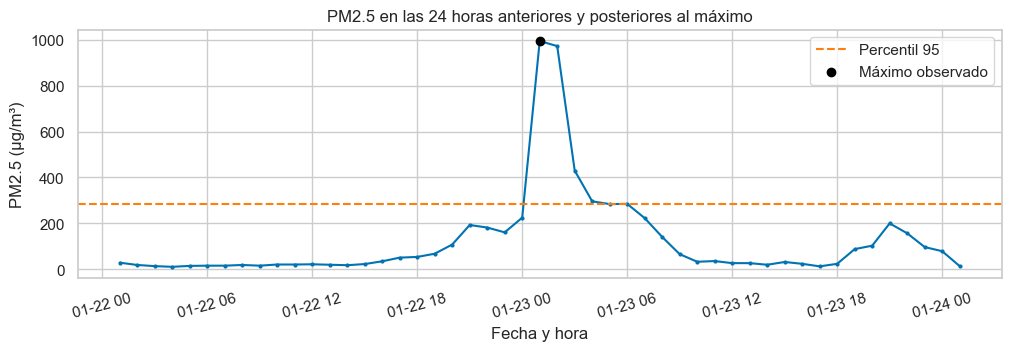

In [12]:
umbral_alto = pm25.quantile(.95)
alto = pm25.ge(umbral_alto)
bloques_altos = alto.ne(alto.shift()).cumsum()
episodios = (
    pm25[alto].reset_index(name="concentracion")
    .assign(bloque=bloques_altos[alto].to_numpy())
    .groupby("bloque")
    .agg(inicio=("fecha", "min"), fin=("fecha", "max"),
         horas=("fecha", "size"), pico=("concentracion", "max"))
    .sort_values(["horas", "pico"], ascending=False)
)
print(f"Umbral exploratorio: {umbral_alto:g} µg/m³ · {len(episodios)} episodios detectados")
display(episodios.head(10).reset_index(drop=True))

hora_pico = pm25.idxmax()
margen_pico = pd.Timedelta(hours=24)
entorno_pico = pm25.loc[hora_pico - margen_pico : hora_pico + margen_pico]
fig, ax = plt.subplots(figsize=(10, 3.4), layout="constrained")
ax.plot(entorno_pico.index, entorno_pico, marker=".", markersize=4)
ax.axhline(umbral_alto, color="tab:orange", linestyle="--", label="Percentil 95")
ax.scatter(hora_pico, pm25.max(), color="black", zorder=3, label="Máximo observado")
ax.set(title="PM2.5 en las 24 horas anteriores y posteriores al máximo",
       xlabel="Fecha y hora", ylabel="PM2.5 (µg/m³)")
ax.legend()
ax.tick_params(axis="x", labelrotation=15)
plt.show()

La evolución alrededor de un pico aporta contexto para revisarlo. La magnitud de una observación por sí sola es insuficiente para decidir que se trata de un error de medición.

## 13. Dirección del viento y PM2.5

Compara cuántas horas hay en cada categoría y cómo se distribuye el PM2.5 medido. La tabla indica también qué proporción de horas de cada grupo tiene una concentración disponible.

,horas,observadas,mediana,p95,Cobertura (%)
cbwd,,,,,
SE,15290,14573,91.0,268.4,95.3
NW,14150,13484,31.0,260.0,95.3
cv,9387,8944,98.0,329.0,95.3
NE,4997,4756,55.0,298.0,95.2


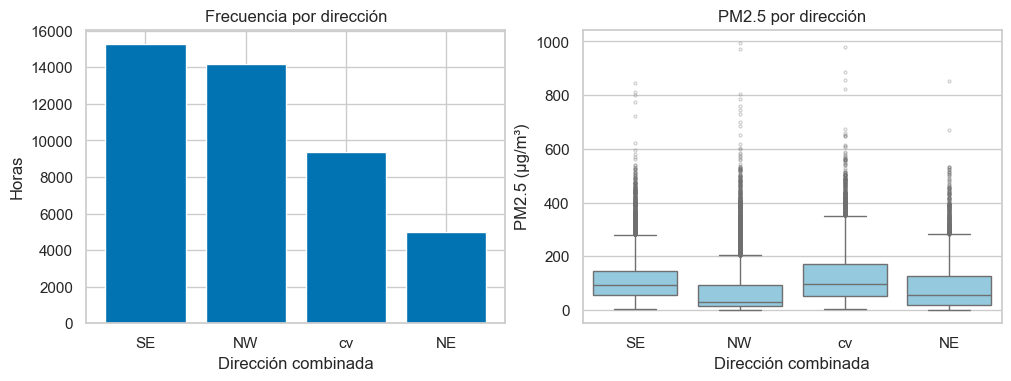

In [13]:
viento = serie.groupby("cbwd")[objetivo].agg(
    horas="size", observadas="count", mediana="median",
    p95=lambda valores: valores.quantile(.95),
).sort_values("horas", ascending=False)
viento["Cobertura (%)"] = 100 * viento["observadas"] / viento["horas"]
display(viento.round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].bar(viento.index, viento["horas"])
axes[0].set(title="Frecuencia por dirección", xlabel="Dirección combinada", ylabel="Horas")
sns.boxplot(data=observadas, x="cbwd", y=objetivo, order=viento.index,
            color="skyblue", flierprops={"markersize": 2, "alpha": 0.3}, ax=axes[1])
axes[1].set(title="PM2.5 por dirección", xlabel="Dirección combinada", ylabel="PM2.5 (µg/m³)")
plt.show()

Las direcciones más frecuentes son SE y NW, pero sus concentraciones típicas son bastante distintas. Con NW la mediana de PM2.5 es de 31, mientras que con SE sube a 91 y con cv llega a 98. Una posible explicación es que, según la dirección del viento, llegue aire de zonas con distintos niveles de contaminación. Como la frecuencia de cada dirección también cambia según el mes, después comparamos las direcciones dentro de cada mes para ver si la diferencia se mantiene.

## 14. Dirección del viento dentro de cada mes

La mezcla de direcciones cambia con el mes. Se compara PM2.5 por dirección dentro de cada mes para comprobar cuánto del patrón agregado persiste al tener en cuenta el calendario. Las celdas indican mediana y número de horas observadas.

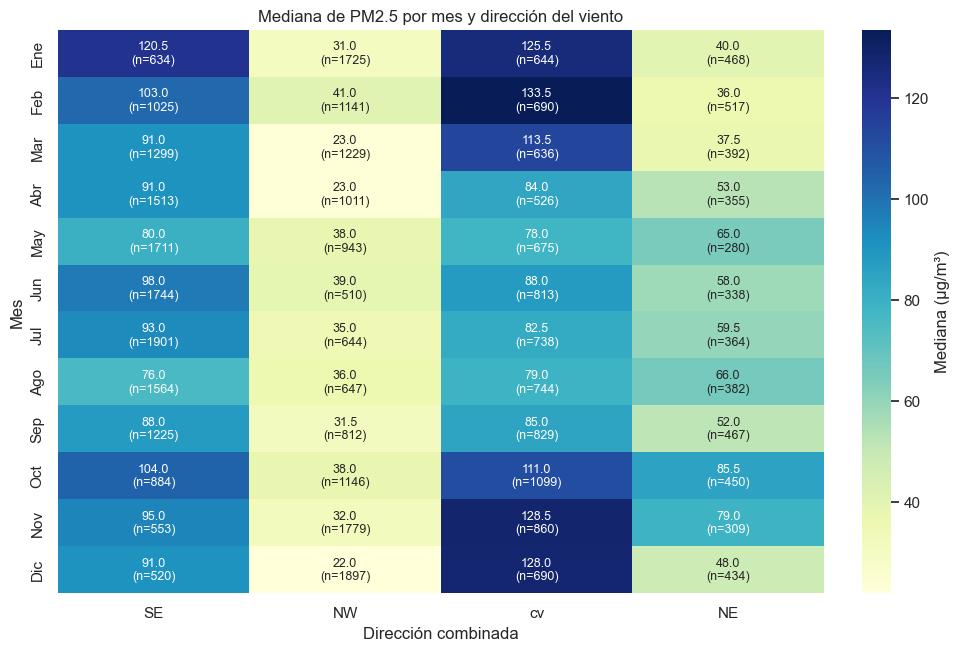

In [14]:
mediana_viento_mes = (
    observadas.groupby(["month", "cbwd"])[objetivo].median()
    .unstack().reindex(index=range(1, 13), columns=viento.index)
)
n_viento_mes = pd.crosstab(observadas["month"], observadas["cbwd"]).reindex_like(mediana_viento_mes)
etiquetas = mediana_viento_mes.round(1).astype(str) + "\n(n=" + n_viento_mes.astype(str) + ")"

fig, ax = plt.subplots(figsize=(9.5, 6.4), layout="constrained")
sns.heatmap(mediana_viento_mes, annot=etiquetas, fmt="", cmap="YlGnBu",
            yticklabels=meses, annot_kws={"fontsize": 9},
            cbar_kws={"label": "Mediana (µg/m³)"}, ax=ax)
ax.set(title="Mediana de PM2.5 por mes y dirección del viento",
       xlabel="Dirección combinada", ylabel="Mes")
plt.show()

Al comparar las direcciones dentro de cada mes, vemos que la mediana de PM2.5 con NW queda por debajo de las de SE y cv en los doce meses. Eso indica que el patrón se mantiene incluso cuando comparamos horas del mismo mes. Una parte de la diferencia podría deberse a que la velocidad acumulada del viento también varía según la dirección. Por eso, en el siguiente apartado miramos cómo se relaciona Iws con el PM2.5.

## 15. Velocidad acumulada del viento y PM2.5

El gráfico de densidad conserva todas las observaciones y reduce la superposición del diagrama de dispersión original. Los cuantiles de `Iws` resumen el recorrido de la mediana sin fijar umbrales físicos para el acumulado.

,observadas,media,mediana
grupo_Iws,,,
"(0.449, 1.78]",8495,138.6,110.0
"(1.78, 3.56]",8257,111.2,86.0
"(3.56, 9.83]",8426,103.0,77.0
"(9.83, 29.49]",8229,85.9,63.0
"(29.49, 565.49]",8350,53.7,27.0


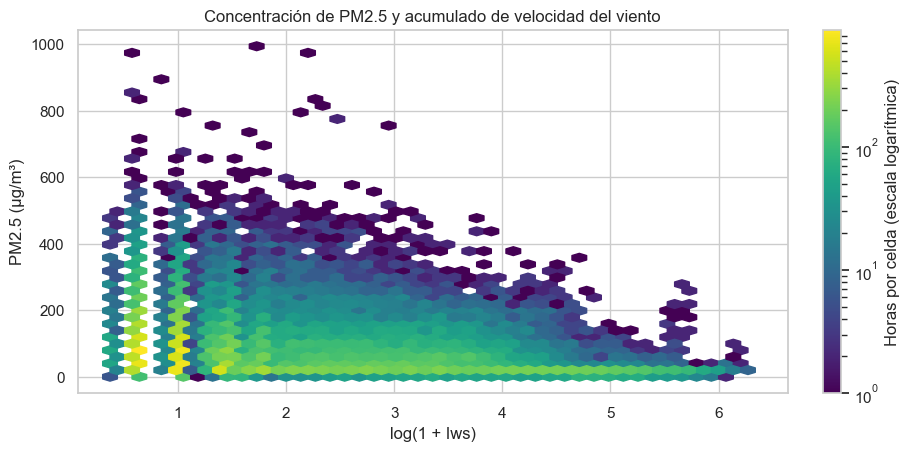

In [15]:
pares_viento = observadas[[objetivo, "Iws"]].dropna().copy()
pares_viento["grupo_Iws"] = pd.qcut(pares_viento["Iws"], q=5, duplicates="drop")
display(pares_viento.groupby("grupo_Iws", observed=True)[objetivo].agg(
    observadas="count", media="mean", mediana="median",
).round(1))

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
densidad = ax.hexbin(
    np.log1p(pares_viento["Iws"]), pares_viento[objetivo],
    gridsize=44, mincnt=1, bins="log", cmap="viridis",
)
fig.colorbar(densidad, ax=ax, label="Horas por celda (escala logarítmica)")
ax.set(title="Concentración de PM2.5 y acumulado de velocidad del viento",
       xlabel="log(1 + Iws)", ylabel="PM2.5 (µg/m³)")
plt.show()

Con valores bajos de Iws aparecen tanto concentraciones bajas como algunos de los picos más altos de PM2.5. A medida que aumenta el acumulado del viento, las concentraciones tienden a ser más bajas y los picos son menos frecuentes. Una posible explicación es que el viento ayude a dispersar las partículas. Como Iws es un acumulado, interpretamos el patrón teniendo en cuenta también la dirección y cuánto tiempo se ha mantenido el viento.

## 16. Asociaciones numéricas y posible redundancia

Usamos la correlación de Pearson para ver qué relación lineal hay entre las variables numéricas. Dejamos fuera el calendario, el identificador y la dirección del viento. Para cada correlación usamos las horas en las que tenemos las dos mediciones.

,Pearson con PM2.5
DEWP,0.171
TEMP,-0.091
PRES,-0.047
Iws,-0.248
Is,0.019
Ir,-0.051


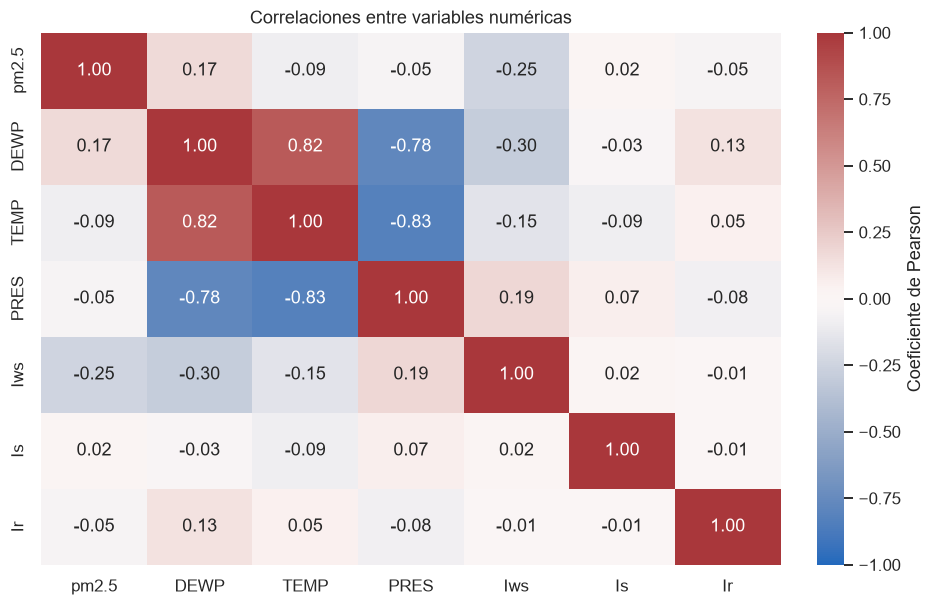

In [16]:
numericas = serie[variables_numericas]
pearson = numericas.corr(method="pearson")

display(pearson[objetivo].drop(objetivo).round(3).to_frame("Pearson con PM2.5"))

fig, ax = plt.subplots(figsize=(8.4, 5.4), layout="constrained")
sns.heatmap(pearson, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            cmap="vlag", cbar_kws={"label": "Coeficiente de Pearson"}, ax=ax)
ax.set_title("Correlaciones entre variables numéricas")
plt.show()

De las variables numéricas, Iws tiene la correlación lineal más fuerte con el PM2.5, de aproximadamente −0,25. Esto va en la misma dirección que el gráfico anterior. Cuando el acumulado del viento es mayor, el PM2.5 tiende a ser más bajo, aunque hay bastante variación.

TEMP y DEWP suelen subir y bajar juntas, con una correlación de aproximadamente 0,82. Puede que las dos recojan parte del mismo patrón estacional. Si las usamos para predecir el PM2.5, podemos probar el modelo con cada una por separado y con las dos juntas para ver si combinarlas mejora la predicción.

## 17. Nieve y lluvia: tamaño de los grupos

Compara PM2.5 cuando el acumulado respectivo es cero o positivo. Una hora con acumulado positivo se interpreta según la definición de la variable. Los tamaños de los grupos ayudan a valorar las diferencias observadas.

In [17]:
resumen_precipitacion = []
for variable, fenomeno in {"Is": "Nieve", "Ir": "Lluvia"}.items():
    pares = observadas[[variable, objetivo]].dropna()
    grupo = pares[variable].gt(0).map({False: "Cero", True: "Positivo"})
    resumen = pares.groupby(grupo)[objetivo].agg(
        observadas="count", mediana="median",
        p25=lambda valores: valores.quantile(.25),
        p75=lambda valores: valores.quantile(.75),
    )
    resumen.index.name = "Acumulado"
    resumen_precipitacion.append(resumen.assign(Fenómeno=fenomeno).reset_index())

display(pd.concat(resumen_precipitacion, ignore_index=True)
        .set_index(["Fenómeno", "Acumulado"]).round(1))

observadas  mediana   p25    p75
Fenómeno Acumulado                                  
Nieve    Cero            41389     72.0  29.0  137.0
         Positivo          368    100.0  69.0  181.8
Lluvia   Cero            40018     72.0  29.0  138.0
         Positivo         1739     72.0  37.0  123.0

## 18. Conclusiones y siguientes pasos

Las mediciones de PM2.5 se parecen mucho entre horas cercanas y cambian según la hora del día y el viento. Para preparar los datos, mantendremos el orden de las horas y dejaremos como ausentes los huecos de varios días.

Si hacemos una predicción a una hora, probaremos si añadir el calendario y la meteorología mejora la predicción que usa la última medición disponible. Entrenaremos con datos anteriores y compararemos los resultados en las mismas horas de un periodo posterior.